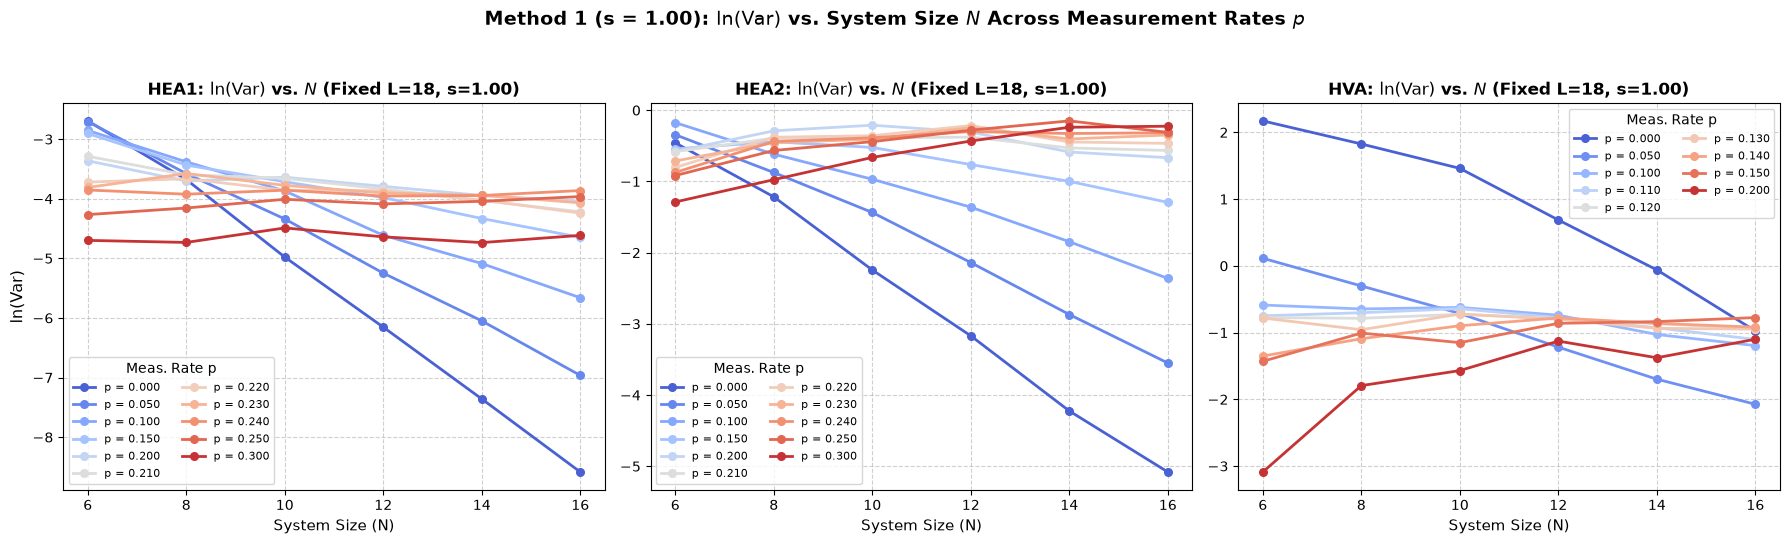

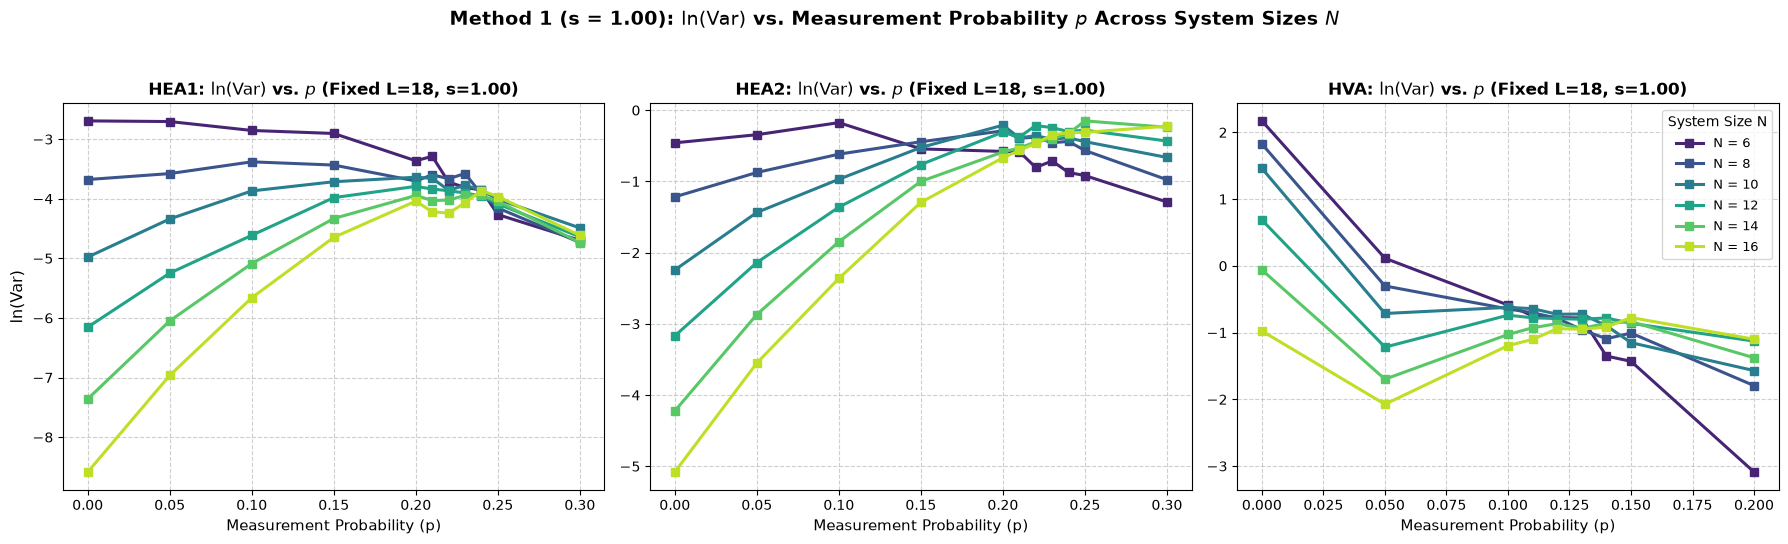

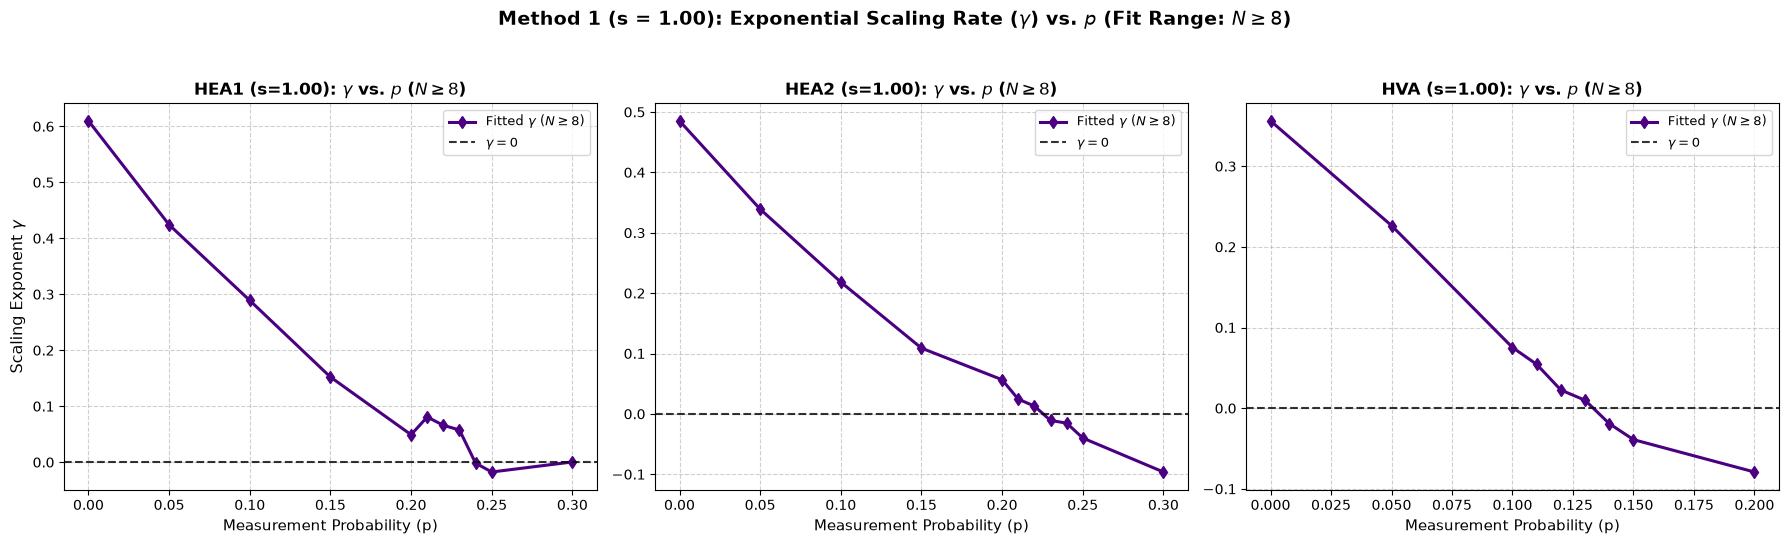

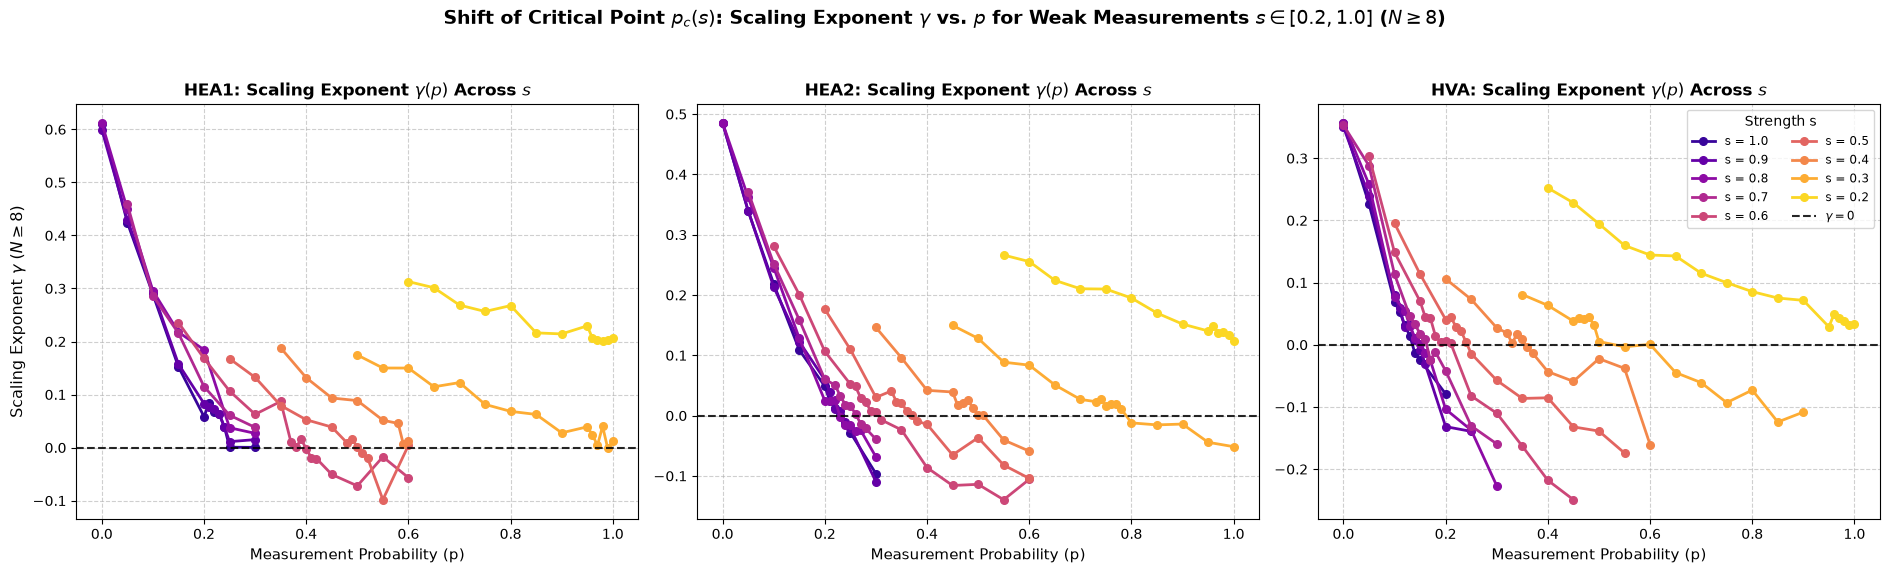

In [2]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

def plot_milt_custom_s_and_p(
    pkl_path="method1_weak_s_xxz_results.pkl",
    s_val=1.0,
    p_filter_by_ansatz=None,
    N_filter=None,
    fit_min_N=6,
    tol=1e-4
):
    """
    Plots for a chosen measurement strength `s_val`:
      1) ln(Var) vs N for selected p values per ansatz
      2) ln(Var) vs p for selected N values per ansatz
      3) Scaling exponent gamma vs p (from fitting ln(Var) = -gamma * N + C over N >= fit_min_N)
    """
    with open(pkl_path, "rb") as f:
        data = pickle.load(f)

    ansatz_list = data["ansatz_list"]
    depth_desc = data.get("depth_desc", "Fixed L=18")

    # Support both multi-s .pkl (variances[s][ansatz][p][N]) and single-s .pkl (variances[ansatz][p][N])
    all_vars = data["variances"]
    if s_val in all_vars:
        variances = all_vars[s_val]
    else:
        # Match closest float key for s_val
        s_keys = [k for k in all_vars.keys() if isinstance(k, (int, float))]
        if s_keys:
            closest_s = min(s_keys, key=lambda k: abs(float(k) - s_val))
            variances = all_vars[closest_s]
            s_val = float(closest_s)
        else:
            variances = all_vars

    def get_valid_ps_and_Ns(ansatz):
        avail_ps = sorted([
            float(p) for p, n_dict in variances[ansatz].items()
            if len(n_dict) > 0
        ])
        if p_filter_by_ansatz and ansatz in p_filter_by_ansatz and p_filter_by_ansatz[ansatz] is not None:
            filt = p_filter_by_ansatz[ansatz]
            if isinstance(filt, tuple) and len(filt) == 2:
                p_min, p_max = filt
                sel_ps = [p for p in avail_ps if (p_min - tol) <= p <= (p_max + tol)]
            else:
                sel_ps = [
                    p for p in avail_ps
                    if any(abs(p - target_p) <= tol for target_p in filt)
                ]
        else:
            sel_ps = avail_ps

        if not sel_ps:
            return np.array([]), np.array([])
        common_Ns = sorted(list(set.intersection(*[
            set(int(n) for n in variances[ansatz][p].keys()) for p in sel_ps
        ])))
        if N_filter is not None:
            common_Ns = [n for n in common_Ns if n in N_filter]
        return np.asarray(sel_ps, dtype=np.float64), np.asarray(common_Ns, dtype=np.int32)

    # =========================================================================
    # 1. PLOT ln(Var) vs N FOR DIFFERENT p (Per-Ansatz Filtered p)
    # =========================================================================
    fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5.5), sharex=False)

    for col_idx, ansatz in enumerate(ansatz_list):
        ax = axes1[col_idx]
        p_sub, N_sub = get_valid_ps_and_Ns(ansatz)
        cmap_p = plt.cm.coolwarm(np.linspace(0.05, 0.95, max(len(p_sub), 1)))

        for p_idx, p_val in enumerate(p_sub):
            var_vs_N = np.asarray([variances[ansatz][float(p_val)][int(N)] for N in N_sub], dtype=np.float64)
            ln_var = np.log(np.maximum(var_vs_N, 1e-30))
            ax.plot(N_sub, ln_var, "o-", color=cmap_p[p_idx], lw=2.0, markersize=5.5, label=f"p = {p_val:.3f}")

        ax.set_title(f"{ansatz}: $\\ln(\\mathrm{{Var}})$ vs. $N$ ({depth_desc}, s={s_val:.2f})", fontsize=12, fontweight="bold")
        ax.set_xlabel("System Size (N)", fontsize=11)
        if col_idx == 0:
            ax.set_ylabel("$\\ln(\\mathrm{Var})$", fontsize=11.5)
        if len(N_sub) > 0:
            ax.set_xticks(N_sub)
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend(loc="best", title="Meas. Rate p", fontsize=8, ncol=2)

    plt.suptitle(f"Method 1 (s = {s_val:.2f}): $\\ln(\\mathrm{{Var}})$ vs. System Size $N$ Across Measurement Rates $p$",
                 fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

    # =========================================================================
    # 2. PLOT ln(Var) vs p FOR DIFFERENT N (Per-Ansatz Filtered p)
    # =========================================================================
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5.5), sharex=False)

    for col_idx, ansatz in enumerate(ansatz_list):
        ax = axes2[col_idx]
        p_sub, N_sub = get_valid_ps_and_Ns(ansatz)
        cmap_N = plt.cm.viridis(np.linspace(0.1, 0.9, max(len(N_sub), 1)))

        for n_idx, N in enumerate(N_sub):
            var_vs_p = np.asarray([variances[ansatz][float(p_val)][int(N)] for p_val in p_sub], dtype=np.float64)
            ln_var = np.log(np.maximum(var_vs_p, 1e-30))
            ax.plot(p_sub, ln_var, "s-", color=cmap_N[n_idx], lw=2.2, markersize=5.5, label=f"N = {N}")

        ax.set_title(f"{ansatz}: $\\ln(\\mathrm{{Var}})$ vs. $p$ ({depth_desc}, s={s_val:.2f})", fontsize=12, fontweight="bold")
        ax.set_xlabel("Measurement Probability (p)", fontsize=11)
        if col_idx == 0:
            ax.set_ylabel("$\\ln(\\mathrm{Var})$", fontsize=11.5)
        ax.grid(True, linestyle="--", alpha=0.6)
        if col_idx == 2:
            ax.legend(loc="best", title="System Size N", fontsize=9.5)

    plt.suptitle(f"Method 1 (s = {s_val:.2f}): $\\ln(\\mathrm{{Var}})$ vs. Measurement Probability $p$ Across System Sizes $N$",
                 fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

    # =========================================================================
    # 3. PLOT gamma vs p FOR THIS s_val (Fit over N >= fit_min_N)
    # =========================================================================
    fig3, axes3 = plt.subplots(1, 3, figsize=(18, 5.5), sharex=False)

    for col_idx, ansatz in enumerate(ansatz_list):
        ax = axes3[col_idx]
        p_sub, N_sub = get_valid_ps_and_Ns(ansatz)
        N_fit = N_sub[N_sub >= fit_min_N]

        gamma_list = []
        for p_val in p_sub:
            var_vs_N = np.asarray([variances[ansatz][float(p_val)][int(N)] for N in N_fit], dtype=np.float64)
            ln_var = np.log(np.maximum(var_vs_N, 1e-30))
            fit_params = np.polyfit(N_fit, ln_var, 1)
            gamma = -fit_params[0]
            gamma_list.append(gamma)

        ax.plot(p_sub, gamma_list, "d-", color="indigo", lw=2.2, markersize=6.5,
                label=f"Fitted $\\gamma$ ($N \\geq {fit_min_N}$)")
        ax.axhline(y=0, color="black", linestyle="--", lw=1.5, alpha=0.8, label="$\\gamma = 0$")

        ax.set_title(f"{ansatz} (s={s_val:.2f}): $\\gamma$ vs. $p$ ($N \\geq {fit_min_N}$)", fontsize=12, fontweight="bold")
        ax.set_xlabel("Measurement Probability (p)", fontsize=11)
        if col_idx == 0:
            ax.set_ylabel("Scaling Exponent $\\gamma$", fontsize=11.5)
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend(loc="best", fontsize=9.5)

    plt.suptitle(f"Method 1 (s = {s_val:.2f}): Exponential Scaling Rate ($\\gamma$) vs. $p$ (Fit Range: $N \\geq {fit_min_N}$)",
                 fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


def plot_gamma_all_s_overlay(
    pkl_path="data_milt/method1_weak_s_xxz_results.pkl",
    s_filter=None,
    p_bounds_by_s=None,
    fit_min_N=6,
    tol=1e-4
):
    """
    Overlays the scaling exponent curves gamma(p) across all measurement strengths s in [0.2, 1.0]
    on a 1x3 figure so you can directly see p_c(s) (where gamma crosses 0) shift right as s decreases!
    
    Parameters
    ----------
    p_bounds_by_s : dict or None
        Optional dict {s_val: (p_min, p_max)} or {s_val: {"HEA1": (p_min, p_max), ...}}
        to trim which p values are shown for each s curve.
    """
    with open(pkl_path, "rb") as f:
        data = pickle.load(f)

    ansatz_list = data["ansatz_list"]
    all_vars = data["variances"]
    s_avail = sorted([float(s) for s in all_vars.keys()], reverse=True)
    if s_filter is not None:
        s_avail = [s for s in s_avail if any(abs(s - sf) <= tol for sf in s_filter)]

    fig, axes = plt.subplots(1, 3, figsize=(19, 5.8), sharey=False)
    cmap_s = plt.cm.plasma(np.linspace(0.08, 0.92, max(len(s_avail), 1)))

    for col_idx, ansatz in enumerate(ansatz_list):
        ax = axes[col_idx]

        for s_idx, s_val in enumerate(s_avail):
            var_s_ans = all_vars[s_val].get(ansatz, {})
            ps = sorted([float(p) for p, nd in var_s_ans.items() if len(nd) > 0])

            # Apply optional custom p bounds per s (and optionally per ansatz)
            if p_bounds_by_s and s_val in p_bounds_by_s and p_bounds_by_s[s_val] is not None:
                b_spec = p_bounds_by_s[s_val]
                if isinstance(b_spec, dict):
                    b_spec = b_spec.get(ansatz, None)
                if isinstance(b_spec, tuple) and len(b_spec) == 2:
                    ps = [p for p in ps if (b_spec[0] - tol) <= p <= (b_spec[1] + tol)]

            gammas, valid_ps = [], []
            for p_val in ps:
                ns = sorted([int(n) for n in var_s_ans[p_val].keys() if int(n) >= fit_min_N])
                if len(ns) >= 2:
                    n_arr = np.asarray(ns, dtype=np.float64)
                    v_arr = np.asarray([var_s_ans[p_val][n] for n in ns], dtype=np.float64)
                    ln_v = np.log(np.maximum(v_arr, 1e-30))
                    slope, _ = np.polyfit(n_arr, ln_v, 1)
                    gammas.append(-slope)
                    valid_ps.append(p_val)

            if valid_ps:
                ax.plot(valid_ps, gammas, "o-", color=cmap_s[s_idx], lw=2.0, markersize=5.5,
                        label=f"s = {s_val:.1f}")

        ax.axhline(y=0, color="black", linestyle="--", lw=1.5, alpha=0.85, label="$\\gamma = 0$")
        ax.set_title(f"{ansatz}: Scaling Exponent $\\gamma(p)$ Across $s$", fontsize=12, fontweight="bold")
        ax.set_xlabel("Measurement Probability (p)", fontsize=11)
        if col_idx == 0:
            ax.set_ylabel(f"Scaling Exponent $\\gamma$ ($N \\geq {fit_min_N}$)", fontsize=11.5)
        ax.grid(True, linestyle="--", alpha=0.6)
        if col_idx == 2:
            ax.legend(loc="best", title="Strength s", fontsize=8.5, ncol=2)

    plt.suptitle(f"Shift of Critical Point $p_c(s)$: Scaling Exponent $\\gamma$ vs. $p$ for Weak Measurements $s \\in [0.2, 1.0]$ ($N \\geq {fit_min_N}$)",
                 fontsize=13.5, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


# =============================================================================
# EXAMPLE USAGE: SET YOUR p BOUNDS AT THE END HERE!
# =============================================================================

# 1. Inspect a specific measurement strength s_val with per-ansatz p bounds:
custom_p_for_single_s = {
    "HEA1": (0.00, 0.30),
    "HEA2": (0.00, 0.30),
    "HVA":  (0.00, 0.20),
}
plot_milt_custom_s_and_p(
    pkl_path="method1_weak_s_xxz_results_f.pkl",
    s_val=1.0,
    p_filter_by_ansatz=custom_p_for_single_s,
    fit_min_N=8
)

# 2. Overlay gamma(p) across all s in [0.2, 1.0] with custom p bounds per s:
custom_p_bounds_by_s = {
    1.0: (0.00, 0.30),
    0.9: (0.00, 0.30),
    0.8: (0.00, 0.30),
    0.7: (0.00, 0.30),
    0.6: (0.00, 0.60),
    0.5: (0.00, 0.60),
    0.4: (0.00, 0.60),
    0.3: (0.35, 1.00),
    0.2: (0.35, 1.00),
}
plot_gamma_all_s_overlay(
    pkl_path="method1_weak_s_xxz_results_f.pkl",
    p_bounds_by_s=custom_p_bounds_by_s,
    fit_min_N=8
)

<>:105: SyntaxWarning: invalid escape sequence '\g'
<>:105: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nimma\AppData\Local\Temp\ipykernel_13148\4159167372.py:105: SyntaxWarning: invalid escape sequence '\g'
  ax.set_title("Phase Boundary ($\gamma$ distinguishable from $0$)", fontsize=12.5, fontweight="bold")


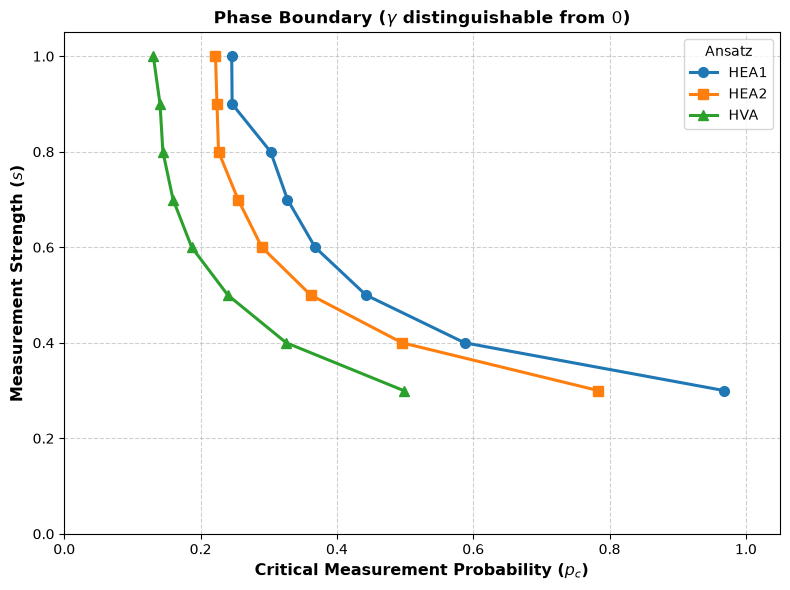

=== INTERPOLATED CRITICAL POINTS p_c(s) ===

[HEA1]
  s = 1.0 --> p_c = 0.2457
  s = 0.9 --> p_c = 0.2463
  s = 0.8 --> p_c = 0.3027
  s = 0.7 --> p_c = 0.3274
  s = 0.6 --> p_c = 0.3680
  s = 0.5 --> p_c = 0.4426
  s = 0.4 --> p_c = 0.5873
  s = 0.3 --> p_c = 0.9680

[HEA2]
  s = 1.0 --> p_c = 0.2218
  s = 0.9 --> p_c = 0.2240
  s = 0.8 --> p_c = 0.2263
  s = 0.7 --> p_c = 0.2549
  s = 0.6 --> p_c = 0.2899
  s = 0.5 --> p_c = 0.3615
  s = 0.4 --> p_c = 0.4955
  s = 0.3 --> p_c = 0.7833

[HVA]
  s = 1.0 --> p_c = 0.1307
  s = 0.9 --> p_c = 0.1405
  s = 0.8 --> p_c = 0.1447
  s = 0.7 --> p_c = 0.1596
  s = 0.6 --> p_c = 0.1869
  s = 0.5 --> p_c = 0.2399
  s = 0.4 --> p_c = 0.3256
  s = 0.3 --> p_c = 0.4978


In [3]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

def compute_and_plot_phase_boundary(
    pkl_path="data_milt/method1_weak_s_xxz_results.pkl",
    fit_min_N=6,
    tol=1e-4
):
    """
    Interpolates the critical measurement rate p_c(s) where gamma transitions
    from being distinguishable from 0 (gamma > error) to indistinguishable 
    (gamma <= error). Plots the 2D phase diagram (p_c vs. s).
    """
    with open(pkl_path, "rb") as f:
        data = pickle.load(f)

    ansatz_list = data["ansatz_list"]
    all_vars = data["variances"]
    
    # Extract sorted list of s values (e.g., 1.0 down to 0.2)
    s_avail = sorted([float(s) for s in all_vars.keys()], reverse=True)

    phase_data = {ansatz: {"s": [], "pc": []} for ansatz in ansatz_list}

    for s_val in s_avail:
        s_dict = all_vars[s_val]
        for ansatz in ansatz_list:
            var_s_ans = s_dict.get(ansatz, {})
            ps = sorted([float(p) for p, nd in var_s_ans.items() if len(nd) > 0])
            if not ps:
                continue

            gammas = []
            errors = []
            valid_ps = []
            for p_val in ps:
                # Require at least 3 points to compute covariance and error reliably
                ns = sorted([int(n) for n in var_s_ans[p_val].keys() if int(n) >= fit_min_N])
                if len(ns) >= 3:
                    n_arr = np.asarray(ns, dtype=np.float64)
                    v_arr = np.asarray([var_s_ans[p_val][n] for n in ns], dtype=np.float64)
                    ln_v = np.log(np.maximum(v_arr, 1e-30))
                    
                    # Fit with cov=True to get the covariance matrix
                    fit_params, cov_matrix = np.polyfit(n_arr, ln_v, 1, cov=True)
                    
                    a = -fit_params[0]          # gamma value
                    b = np.sqrt(cov_matrix[0, 0]) # error in gamma (standard error of slope)
                    
                    gammas.append(a)
                    errors.append(b)
                    valid_ps.append(p_val)

            if len(valid_ps) < 2:
                continue

            # Find transition where (a - b) crosses zero
            # D = a - b. 
            # If D > 0, gamma is distinguishable from zero.
            # If D < 0, gamma is indistinguishable from zero.
            for i in range(len(valid_ps) - 1):
                a1, b1 = gammas[i], errors[i]
                a2, b2 = gammas[i+1], errors[i+1]
                p1, p2 = valid_ps[i], valid_ps[i+1]
                
                D1 = a1 - b1
                D2 = a2 - b2
                
                # Check if the distinguishability metric crosses zero
                if D1 * D2 <= 0 and (D1 != D2):
                    # Linear interpolation for root where D = 0: p_c = p1 - D1 * (p2 - p1) / (D2 - D1)
                    pc_interp = p1 - D1 * (p2 - p1) / (D2 - D1)
                    
                    # Ensure gamma is near zero and >= 0 as a sanity check before accepting
                    gamma_interp = a1 + (a2 - a1) * (pc_interp - p1) / (p2 - p1)
                    if gamma_interp >= -tol: 
                        phase_data[ansatz]["s"].append(s_val)
                        phase_data[ansatz]["pc"].append(pc_interp)
                        break  # Take the first transition encountered

    # =========================================================================
    # PLOT THE 2D PHASE BOUNDARY (p_c vs. s)
    # =========================================================================
    fig, ax = plt.subplots(figsize=(8, 6))

    marker_styles = {"HEA1": "o-", "HEA2": "s-", "HVA": "^-"}
    color_styles = {"HEA1": "tab:blue", "HEA2": "tab:orange", "HVA": "tab:green"}

    for ansatz in ansatz_list:
        s_vals = np.asarray(phase_data[ansatz]["s"])
        pc_vals = np.asarray(phase_data[ansatz]["pc"])

        if len(s_vals) > 0:
            sort_idx = np.argsort(s_vals)
            ax.plot(
               pc_vals[sort_idx], s_vals[sort_idx],
                marker_styles.get(ansatz, "d-"),
                color=color_styles.get(ansatz, "indigo"),
                lw=2.2, markersize=7, label=f"{ansatz}"
            )

    ax.set_ylabel("Measurement Strength ($s$)", fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Critical Measurement Probability ($p_c$)", fontsize=11.5, fontweight="bold")
    ax.set_title("Phase Boundary ($\gamma$ distinguishable from $0$)", fontsize=12.5, fontweight="bold")
    
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.set_xlim(0.0, 1.05)
    ax.set_ylim(0.0, 1.05)
    ax.legend(loc="best", title="Ansatz", fontsize=10)

    plt.tight_layout()
    plt.show()

    print("=== INTERPOLATED CRITICAL POINTS p_c(s) ===")
    for ansatz in ansatz_list:
        print(f"\n[{ansatz}]")
        for s_val, pc_val in zip(phase_data[ansatz]["s"], phase_data[ansatz]["pc"]):
            print(f"  s = {s_val:.1f} --> p_c = {pc_val:.4f}")

# Example execution:
compute_and_plot_phase_boundary(pkl_path="method1_weak_s_xxz_results_f.pkl", fit_min_N=8)